In [ ]:

import json
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision

from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from google.colab import drive

drive.mount("/content/drive")

SEED = 4
EPOCHS = 15
BATCH_SIZE = 50

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

SAVE_DIR = Path("/content/drive/MyDrive/ACM_Trailcam/Transfer_Learning")
SAVE_DIR.mkdir(parents=True, exist_ok=True)


Mounted at /content/drive
Device: cuda


In [ ]:

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4),
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

torchvision.datasets.CIFAR10.url = (
    "https://huggingface.co/datasets/MIT-OL-AI-D/"
    "cifar-10-python/resolve/main/cifar-10-python.tar.gz"
)

train_full = torchvision.datasets.CIFAR10(
    "./data", train=True, download=True,
    transform=train_transform
)

val_full = torchvision.datasets.CIFAR10(
    "./data", train=True, download=False,
    transform=test_transform
)

test_data = torchvision.datasets.CIFAR10(
    "./data", train=False, download=True,
    transform=test_transform
)

indices = torch.randperm(
    50000, generator=torch.Generator().manual_seed(4)
).tolist()

train_ids = indices[:45000]
val_ids = indices[45000:]

train_loader = DataLoader(
    Subset(train_full, train_ids),
    batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=True
)

val_loader = DataLoader(
    Subset(val_full, val_ids),
    batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True
)

test_loader = DataLoader(
    test_data, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)

print("Training images:", len(train_ids))
print("Validation images:", len(val_ids))
print("Test images:", len(test_data))


100%|██████████| 170M/170M [00:01<00:00, 138MB/s]


Training images: 45000
Validation images: 5000
Test images: 10000


In [ ]:

weights = MobileNet_V2_Weights.DEFAULT
model = mobilenet_v2(weights=weights)

model.classifier[1] = nn.Linear(
    model.last_channel, 10
)

for param in model.features.parameters():
    param.requires_grad = False

for block in model.features[-2:]:
    for param in block.parameters():
        param.requires_grad = True

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW([
    {
        "params": [
            p for block in model.features[-2:]
            for p in block.parameters()
        ],
        "lr": 1e-4
    },
    {
        "params": model.classifier.parameters(),
        "lr": 3e-4
    }
], weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS
)

scaler = torch.amp.GradScaler(
    "cuda", enabled=(device.type == "cuda")
)

print("Trainable parameters:", sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
))


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 187MB/s]


Trainable parameters: 898890


In [ ]:

BEST = SAVE_DIR / "mobilenetv2_best.pt"
LAST = SAVE_DIR / "mobilenetv2_last.pt"
HISTORY = SAVE_DIR / "mobilenetv2_history.json"

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

start_epoch = 0
best_val = -1.0

if LAST.exists():
    saved = torch.load(
        LAST, map_location=device, weights_only=True
    )
    model.load_state_dict(saved["model"])
    optimizer.load_state_dict(saved["optimizer"])
    scheduler.load_state_dict(saved["scheduler"])
    scaler.load_state_dict(saved["scaler"])
    history = saved["history"]
    start_epoch = saved["epoch"]
    best_val = saved["best_val"]
    print("Resuming at epoch", start_epoch + 1)

def evaluate(model, loader):
    model.eval()
    loss_sum = correct = total = 0

    with torch.inference_mode():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            output = model(x)
            loss = criterion(output, y)

            loss_sum += loss.item() * y.size(0)
            correct += (output.argmax(1) == y).sum().item()
            total += y.size(0)

    return loss_sum / total, 100 * correct / total

for epoch in range(start_epoch, EPOCHS):
    model.train()

    for block in model.features[:-2]:
        block.eval()

    total_loss = correct = total = 0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            enabled=(device.type == "cuda")
        ):
            output = model(x)
            loss = criterion(output, y)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * y.size(0)
        correct += (output.argmax(1) == y).sum().item()
        total += y.size(0)

    train_loss = total_loss / total
    train_acc = 100 * correct / total

    val_loss, val_acc = evaluate(model, val_loader)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    if val_acc > best_val:
        best_val = val_acc
        torch.save(model.state_dict(), BEST)

    scheduler.step()

    torch.save({
        "epoch": epoch + 1,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "scaler": scaler.state_dict(),
        "history": history,
        "best_val": best_val
    }, LAST)

    HISTORY.write_text(json.dumps(history, indent=2))

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train: {train_acc:.2f}% | "
        f"Validation: {val_acc:.2f}%"
    )

print("Best validation accuracy:", best_val)


Epoch 1/15 | Train: 77.56% | Validation: 84.92%
Epoch 2/15 | Train: 83.82% | Validation: 86.06%
Epoch 3/15 | Train: 85.47% | Validation: 86.52%
Epoch 4/15 | Train: 86.66% | Validation: 87.66%
Epoch 5/15 | Train: 87.64% | Validation: 87.70%
Epoch 6/15 | Train: 88.33% | Validation: 87.62%
Epoch 7/15 | Train: 88.79% | Validation: 88.52%
Epoch 8/15 | Train: 89.44% | Validation: 88.32%
Epoch 9/15 | Train: 89.94% | Validation: 88.42%
Epoch 10/15 | Train: 90.26% | Validation: 88.48%
Epoch 11/15 | Train: 90.56% | Validation: 88.62%
Epoch 12/15 | Train: 90.58% | Validation: 88.72%
Epoch 13/15 | Train: 90.75% | Validation: 88.58%
Epoch 14/15 | Train: 91.15% | Validation: 88.74%
Epoch 15/15 | Train: 91.10% | Validation: 88.62%
Best validation accuracy: 88.74


Your best CNN: 83.87%
MobileNetV2: 89.19%
Difference: +5.32 percentage points


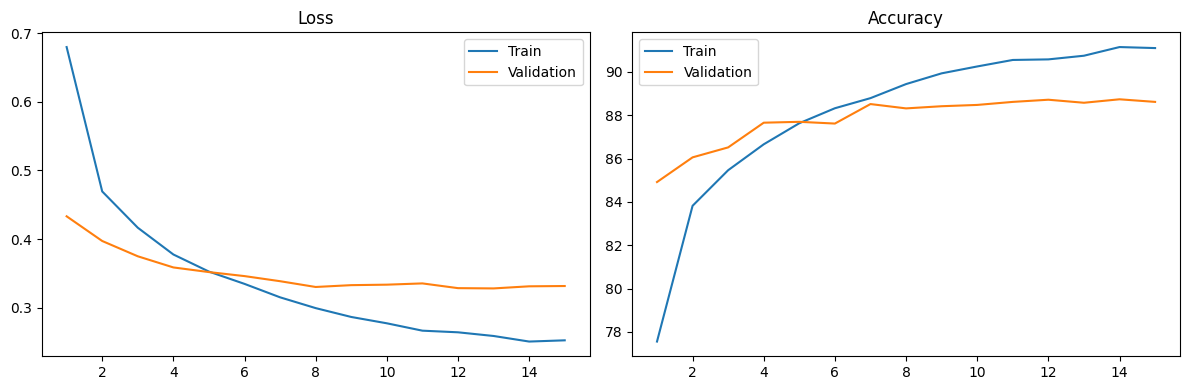

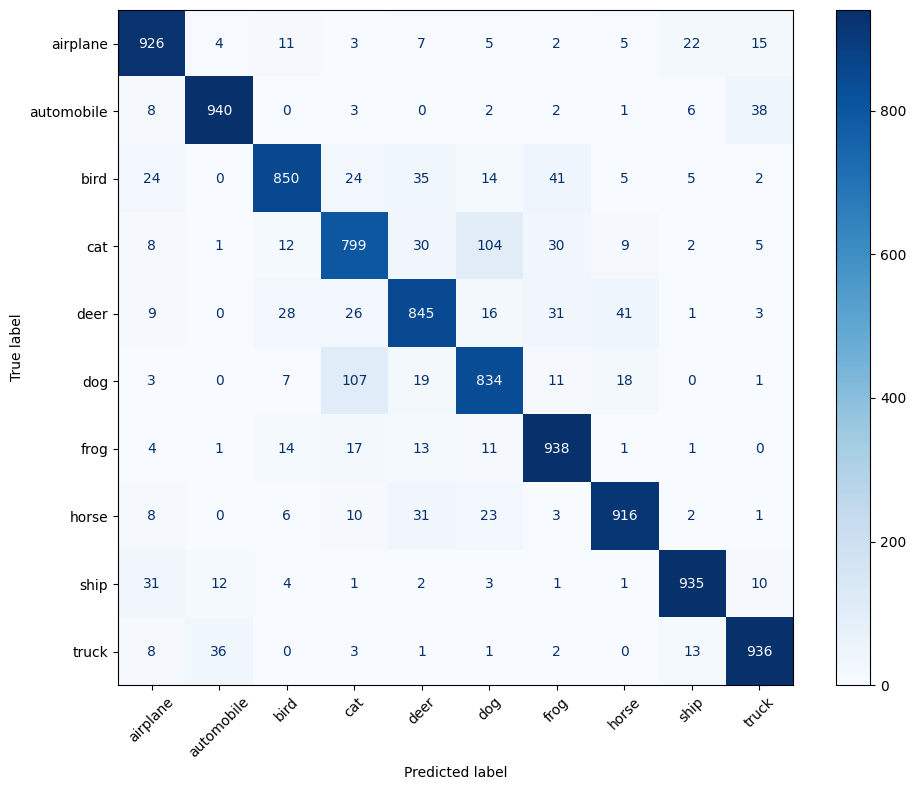

152

In [ ]:

model.load_state_dict(
    torch.load(BEST, map_location=device, weights_only=True)
)

test_loss, test_acc = evaluate(model, test_loader)

baseline = 83.87

print(f"Self trained CNN: {baseline:.2f}%")
print(f"MobileNetV2: {test_acc:.2f}%")
print(f"Difference: {test_acc - baseline:+.2f} percentage points")

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_loss"], label="Train")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(epochs, history["train_accuracy"], label="Train")
axes[1].plot(epochs, history["val_accuracy"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig(SAVE_DIR / "mobilenetv2_curves.png")
plt.show()

actual, predicted = [], []

model.eval()
with torch.inference_mode():
    for x, y in test_loader:
        outputs = model(x.to(device))
        pred = outputs.argmax(1).cpu()
        actual.extend(y.tolist())
        predicted.extend(pred.tolist())

matrix = confusion_matrix(actual, predicted)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    matrix, display_labels=test_data.classes
).plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.tight_layout()
plt.savefig(SAVE_DIR / "mobilenetv2_confusion_matrix.png")
plt.show()

results = {
    "baseline_test_accuracy": baseline,
    "mobilenetv2_test_accuracy": round(test_acc, 2),
    "best_validation_accuracy": round(best_val, 2),
    "difference_percentage_points": round(test_acc - baseline, 2)
}

(SAVE_DIR / "mobilenetv2_results.json").write_text(
    json.dumps(results, indent=2)
)
